[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_hashrate_check/BA_L1_hashrate_check.ipynb)

# BA_L1_hashrate_check: Checking the Hash-Rate Formula on the Data

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

The reported Bitcoin hash rate against the hash rate implied by the published difficulty, D x 2^32 / 600, monthly means, November 2014 to October 2025, and their ratio.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

A Bitcoin block is valid if the hash of its header is below a target $T$; one try succeeds with probability
$T/2^{256}$, so the expected number of tries is $2^{256}/T = D \cdot 2^{32}$, where $D$ is the **difficulty**
published in every block. With one block every 600 seconds, the difficulty implies the network **hash rate**

$$\hat H = \frac{D \cdot 2^{32}}{600} \text{ hashes per second}.$$

The chart compares $\hat H$ with the reported hash rate, monthly means of the daily series, in exahashes per second
(EH/s, $10^{18}$ hashes per second).

**How to read the chart.** Left: both series on a log scale. Right: the ratio reported / implied; a ratio above 1
means that blocks arrived faster than every 600 seconds.

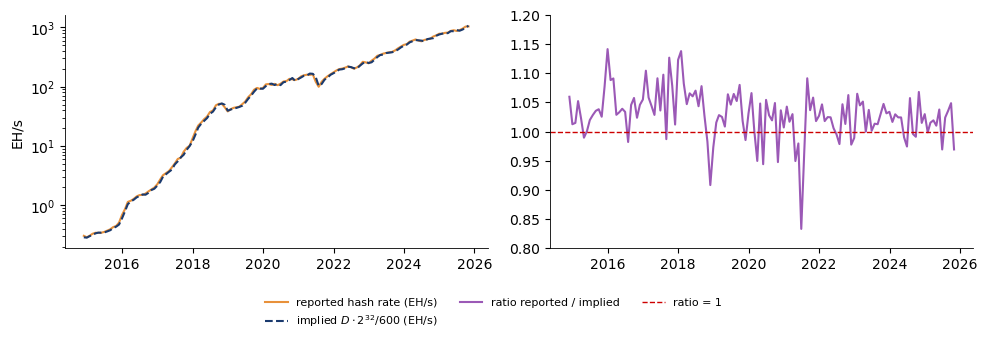

In [5]:
hr, dif = load_onchain('hashrate')['BTC'], load_onchain('miningdifi')['BTC']
implied = dif * 2 ** 32 / 600
mh = pd.DataFrame({'rep': hr, 'imp': implied}).resample('ME').mean().dropna()
rr = mh['rep'] / mh['imp']

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(mh.index, mh['rep'] / 1e18, color=BTC, label='reported hash rate (EH/s)')
ax[0].plot(mh.index, mh['imp'] / 1e18, color=BLUE, ls='--', label=r'implied $D\cdot 2^{32}/600$ (EH/s)')
ax[0].set_yscale('log'); ax[0].set_ylabel('EH/s')
ax[1].plot(rr.index, rr, color=ETH, label='ratio reported / implied')
ax[1].axhline(1, color=RED, ls='--', lw=1, label='ratio = 1')
ax[1].set_ylim(0.8, 1.2)
slide_legend(fig, 0.14)
save_fig(fig, 'ba_l1_hashrate_check')

In [6]:
print(f'Months: {len(mh)}, {mh.index[0]:%b %Y} to {mh.index[-1]:%b %Y}')
print(f'Ratio reported / implied: mean {rr.mean():.3f}, standard deviation {rr.std():.3f}, '
      f'minimum {rr.min():.2f}, maximum {rr.max():.2f}')

Months: 132, Nov 2014 to Oct 2025
Ratio reported / implied: mean 1.029, standard deviation 0.042, minimum 0.83, maximum 1.14
